In [1]:
import pandas as pd

cols = ['engine_id', 'cycle'] + \
       [f'op{i}' for i in range(1,4)] + \
       [f'sensor{i}' for i in range(1,22)]

df = pd.read_csv('CMAPSSData/train_FD001.txt', sep=r'\s+', header=None)

df.columns = cols

df.head()

,engine_id,cycle,op1,op2,op3,sensor1,sensor2,sensor3,sensor4,sensor5,...,sensor12,sensor13,sensor14,sensor15,sensor16,sensor17,sensor18,sensor19,sensor20,sensor21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [ ]:
# Compute RUL

max_cycle = df.groupby('engine_id')['cycle'].max().reset_index()
max_cycle.columns = ['engine_id', 'max_cycle']

df = df.merge(max_cycle, on='engine_id')

df['RUL'] = df['max_cycle'] - df['cycle']

df[['engine_id', 'cycle', 'max_cycle', 'RUL']].head()

,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187


In [3]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# feature columns
feature_cols = [col for col in df.columns if col.startswith('op') or col.startswith('sensor')]

# normalize
scaler = StandardScaler()
df[feature_cols] = scaler.fit_transform(df[feature_cols])

# create sliding windows
window_size = 30

def create_sequences(data, feature_cols, window_size):
    X, y = [], []

    for engine_id in data['engine_id'].unique():
        engine_data = data[data['engine_id'] == engine_id].sort_values('cycle')
        features = engine_data[feature_cols].values
        rul = engine_data['RUL'].values

        for i in range(len(engine_data) - window_size + 1):
            X.append(features[i:i+window_size])
            y.append(rul[i+window_size-1])

    return np.array(X), np.array(y)

X, y = create_sequences(df, feature_cols, window_size)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (17731, 30, 24)
y shape: (17731,)


spectrogram shape: (6, 7)


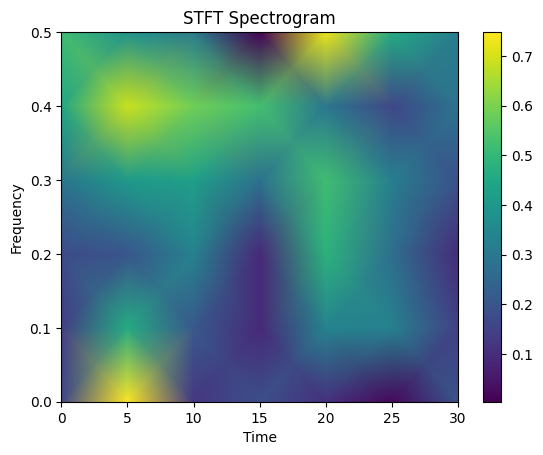

In [4]:
from scipy.signal import stft
import matplotlib.pyplot as plt
import numpy as np

# take one sample, one sensor
signal = X[0, :, 0]

f, t, Zxx = stft(signal, nperseg=10)
spectrogram = np.abs(Zxx)

print("spectrogram shape:", spectrogram.shape)

plt.pcolormesh(t, f, spectrogram, shading='gouraud')
plt.xlabel("Time")
plt.ylabel("Frequency")
plt.title("STFT Spectrogram")
plt.colorbar()
plt.show()

In [5]:
from scipy.signal import stft
import numpy as np

def create_spectrogram_sequences(X, nperseg=10):
    X_spec = []

    for sample in X:  # sample shape: (window_size, num_features)
        sensor_specs = []

        for j in range(sample.shape[1]):  # each feature/sensor
            signal = sample[:, j]
            f, t, Zxx = stft(signal, nperseg=nperseg)
            sensor_specs.append(np.abs(Zxx))  # magnitude spectrogram

        sensor_specs = np.array(sensor_specs)   # (num_features, freq_bins, time_bins)
        X_spec.append(sensor_specs)

    return np.array(X_spec)

X_spec = create_spectrogram_sequences(X, nperseg=10)
print("X_spec shape:", X_spec.shape)

X_spec shape: (17731, 24, 6, 7)


In [6]:
import numpy as np

def extract_lr_features(X):
    feats = []
    for sample in X:
        mean = sample.mean(axis=0)
        std  = sample.std(axis=0)
        last = sample[-1, :]
        feats.append(np.concatenate([mean, std, last]))
    return np.array(feats)

X_lr = extract_lr_features(X)
print("LR feature shape:", X_lr.shape)

LR feature shape: (17731, 72)


In [7]:
from sklearn.model_selection import train_test_split

Xtr, Xva, ytr, yva = train_test_split(X_lr, y, test_size=0.2, random_state=42)

In [8]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(Xtr, ytr)
y_pred_lr = lr.predict(Xva)

In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

mse  = mean_squared_error(yva, y_pred_lr)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(yva, y_pred_lr)
r2   = r2_score(yva, y_pred_lr)

print("Linear Regression Results")
print("MSE :", mse)
print("RMSE:", rmse)
print("MAE :", mae)
print("R2  :", r2)

Linear Regression Results
MSE : 1408.4178295309773
RMSE: 37.52889326280456
MAE : 28.14070259660911
R2  : 0.6318449231129843


In [10]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# tensor
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t   = torch.tensor(X_val, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1,1)
y_val_t   = torch.tensor(y_val, dtype=torch.float32).view(-1,1)

# loader
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                          batch_size=64, shuffle=True)

val_loader = DataLoader(TensorDataset(X_val_t, y_val_t),
                        batch_size=64, shuffle=False)

Device: cuda


In [11]:
import torch.nn as nn

class LSTMRegressor(nn.Module):
    def __init__(self, input_size=24, hidden_size=64, num_layers=2):
        super().__init__()
        
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)          # (batch, seq, hidden)
        out = out[:, -1, :]            # 取最后一个时间步
        out = self.fc(out)
        return out

model = LSTMRegressor().to(device)
print(model)

LSTMRegressor(
  (lstm): LSTM(24, 64, num_layers=2, batch_first=True)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def train_model(model, train_loader, val_loader, epochs=15):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    for epoch in range(epochs):
        # train 
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # Validation
        model.eval()
        preds = []
        targets = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                pred = model(xb)

                preds.append(pred.cpu().numpy())
                targets.append(yb.numpy())

        preds = np.vstack(preds).ravel()
        targets = np.vstack(targets).ravel()

        mse = mean_squared_error(targets, preds)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(targets, preds)
        r2 = r2_score(targets, preds)

        print(f"Epoch {epoch+1}")
        print(f"Train Loss: {np.mean(train_losses):.4f}")
        print(f"RMSE: {rmse:.2f} | MAE: {mae:.2f} | R2: {r2:.3f}")
        print("-"*40)

    return model

In [13]:
model = train_model(model, train_loader, val_loader, epochs=25)

Epoch 1
Train Loss: 6497.5135
RMSE: 39.99 | MAE: 27.58 | R2: 0.582
----------------------------------------
Epoch 2
Train Loss: 1377.1041
RMSE: 33.50 | MAE: 23.61 | R2: 0.707
----------------------------------------
Epoch 3
Train Loss: 1093.3259
RMSE: 29.57 | MAE: 20.51 | R2: 0.772
----------------------------------------
Epoch 4
Train Loss: 927.9099
RMSE: 27.91 | MAE: 19.21 | R2: 0.796
----------------------------------------
Epoch 5
Train Loss: 892.1530
RMSE: 26.29 | MAE: 17.82 | R2: 0.819
----------------------------------------
Epoch 6
Train Loss: 814.9927
RMSE: 25.84 | MAE: 17.93 | R2: 0.825
----------------------------------------
Epoch 7
Train Loss: 787.2271
RMSE: 23.90 | MAE: 16.32 | R2: 0.851
----------------------------------------
Epoch 8
Train Loss: 714.1040
RMSE: 24.15 | MAE: 16.64 | R2: 0.848
----------------------------------------
Epoch 9
Train Loss: 694.7599
RMSE: 24.97 | MAE: 16.81 | R2: 0.837
----------------------------------------
Epoch 10
Train Loss: 613.5967
RMSE

In [14]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Conv1d expects: (batch, channels, length)
X_train_t = torch.tensor(X_train, dtype=torch.float32).permute(0, 2, 1)
X_val_t   = torch.tensor(X_val, dtype=torch.float32).permute(0, 2, 1)

y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_val_t   = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=64,
    shuffle=False
)

print("X_train_t shape:", X_train_t.shape)  # should be (N, 24, 30)
print("X_val_t shape:", X_val_t.shape)

Device: cuda
X_train_t shape: torch.Size([14184, 24, 30])
X_val_t shape: torch.Size([3547, 24, 30])


In [ ]:
import torch.nn as nn

class CNN1DRegressor(nn.Module):
    def __init__(self, in_channels=24):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(in_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )

        # input length = 30
        # after pool1: 30 to 15
        # after pool2: 15 to 7
        self.regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.regressor(x)
        return x

model_1dcnn = CNN1DRegressor(in_channels=24).to(device)
print(model_1dcnn)

CNN1DRegressor(
  (features): Sequential(
    (0): Conv1d(24, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (regressor): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=448, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def train_model(model, train_loader, val_loader, epochs=15, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            preds = model(xb)
            loss = criterion(preds, yb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        model.eval()
        preds_all = []
        targets_all = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                preds = model(xb)

                preds_all.append(preds.cpu().numpy())
                targets_all.append(yb.numpy())

        preds_all = np.vstack(preds_all).ravel()
        targets_all = np.vstack(targets_all).ravel()

        mse = mean_squared_error(targets_all, preds_all)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(targets_all, preds_all)
        r2 = r2_score(targets_all, preds_all)

        print(f"Epoch {epoch+1}/{epochs}")
        print(f"Train Loss: {np.mean(train_losses):.4f}")
        print(f"RMSE: {rmse:.2f} | MAE: {mae:.2f} | R2: {r2:.3f}")
        print("-" * 40)

    return model, preds_all, targets_all

In [17]:
model_1dcnn, preds_1dcnn, targets_1dcnn = train_model(
    model_1dcnn,
    train_loader,
    val_loader,
    epochs=25,
    lr=1e-3
)

Epoch 1/25
Train Loss: 2844.3025
RMSE: 39.84 | MAE: 29.39 | R2: 0.585
----------------------------------------
Epoch 2/25
Train Loss: 1582.7786
RMSE: 38.92 | MAE: 27.86 | R2: 0.604
----------------------------------------
Epoch 3/25
Train Loss: 1484.0452
RMSE: 37.18 | MAE: 26.96 | R2: 0.639
----------------------------------------
Epoch 4/25
Train Loss: 1347.7235
RMSE: 34.45 | MAE: 24.50 | R2: 0.690
----------------------------------------
Epoch 5/25
Train Loss: 1129.2462
RMSE: 31.04 | MAE: 20.91 | R2: 0.748
----------------------------------------
Epoch 6/25
Train Loss: 1057.4969
RMSE: 30.04 | MAE: 20.40 | R2: 0.764
----------------------------------------
Epoch 7/25
Train Loss: 971.2338
RMSE: 29.23 | MAE: 20.10 | R2: 0.777
----------------------------------------
Epoch 8/25
Train Loss: 920.6344
RMSE: 28.71 | MAE: 19.94 | R2: 0.785
----------------------------------------
Epoch 9/25
Train Loss: 879.3234
RMSE: 28.96 | MAE: 19.65 | R2: 0.781
----------------------------------------
Epoc

In [18]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Xtr, Xva, ytr, yva = train_test_split(
    X_spec, y, test_size=0.2, random_state=42
)

Xtr_t = torch.tensor(Xtr, dtype=torch.float32)
Xva_t = torch.tensor(Xva, dtype=torch.float32)

ytr_t = torch.tensor(ytr, dtype=torch.float32).view(-1, 1)
yva_t = torch.tensor(yva, dtype=torch.float32).view(-1, 1)

train_loader_2d = DataLoader(
    TensorDataset(Xtr_t, ytr_t), batch_size=64, shuffle=True
)
val_loader_2d = DataLoader(
    TensorDataset(Xva_t, yva_t), batch_size=64, shuffle=False
)

print("Train:", Xtr_t.shape, ytr_t.shape)
print("Val  :", Xva_t.shape, yva_t.shape)

Train: torch.Size([14184, 24, 6, 7]) torch.Size([14184, 1])
Val  : torch.Size([3547, 24, 6, 7]) torch.Size([3547, 1])


In [19]:
import torch.nn as nn

class CNN2DRegressor(nn.Module):
    def __init__(self, in_channels=24):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),   # (6,7) -> (3,3)

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU()
        )

        self.regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.regressor(x)
        return x

model_2d = CNN2DRegressor().to(device)
print(model_2d)

CNN2DRegressor(
  (features): Sequential(
    (0): Conv2d(24, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
  )
  (regressor): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=576, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

def train_model_2d(model, train_loader, val_loader, epochs=25, lr=1e-3):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_rmse = float("inf")
    best_epoch = 0

    for epoch in range(epochs):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # Validation
        model.eval()
        preds, targets = [], []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                pred = model(xb)

                preds.append(pred.cpu().numpy())
                targets.append(yb.numpy())

        preds = np.vstack(preds).ravel()
        targets = np.vstack(targets).ravel()

        mse = mean_squared_error(targets, preds)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(targets, preds)
        r2 = r2_score(targets, preds)

        if rmse < best_rmse:
            best_rmse = rmse
            best_epoch = epoch + 1

        print(f"Epoch {epoch+1}/{epochs}")
        print(f"Train Loss: {np.mean(train_losses):.4f}")
        print(f"RMSE: {rmse:.2f} | MAE: {mae:.2f} | R2: {r2:.3f}")
        print("-"*40)

    print("Best Epoch:", best_epoch)
    print("Best RMSE :", best_rmse)

    return best_rmse

In [21]:
best_rmse_2d = train_model_2d(
    model_2d,
    train_loader_2d,
    val_loader_2d,
    epochs=25
)

Epoch 1/25
Train Loss: 4289.1300
RMSE: 56.37 | MAE: 43.72 | R2: 0.169
----------------------------------------
Epoch 2/25
Train Loss: 2852.2542
RMSE: 49.49 | MAE: 37.98 | R2: 0.360
----------------------------------------
Epoch 3/25
Train Loss: 2311.0249
RMSE: 45.39 | MAE: 34.79 | R2: 0.461
----------------------------------------
Epoch 4/25
Train Loss: 2047.3431
RMSE: 43.24 | MAE: 32.66 | R2: 0.511
----------------------------------------
Epoch 5/25
Train Loss: 1846.9808
RMSE: 42.89 | MAE: 32.99 | R2: 0.519
----------------------------------------
Epoch 6/25
Train Loss: 1750.2860
RMSE: 42.19 | MAE: 32.58 | R2: 0.535
----------------------------------------
Epoch 7/25
Train Loss: 1681.5986
RMSE: 39.43 | MAE: 28.61 | R2: 0.594
----------------------------------------
Epoch 8/25
Train Loss: 1573.9904
RMSE: 38.35 | MAE: 28.04 | R2: 0.616
----------------------------------------
Epoch 9/25
Train Loss: 1517.6854
RMSE: 37.52 | MAE: 27.65 | R2: 0.632
----------------------------------------
E

In [22]:
# Import linear regression model
from sklearn.linear_model import LinearRegression

# Create the model
lr = LinearRegression()

In [26]:
# Flatten ORIGINAL time-domain data (before CNN reshaping)
Xtr_lr = Xtr.reshape(Xtr.shape[0], -1)
Xva_lr = Xva.reshape(Xva.shape[0], -1)

# Train model
lr = LinearRegression()
lr.fit(Xtr_lr, ytr)

# Predict
y_pred_lr = lr.predict(Xva_lr)

In [27]:
print("yva shape:", yva.shape)
print("y_pred_lr shape:", y_pred_lr.shape)

yva shape: (3547,)
y_pred_lr shape: (3547,)


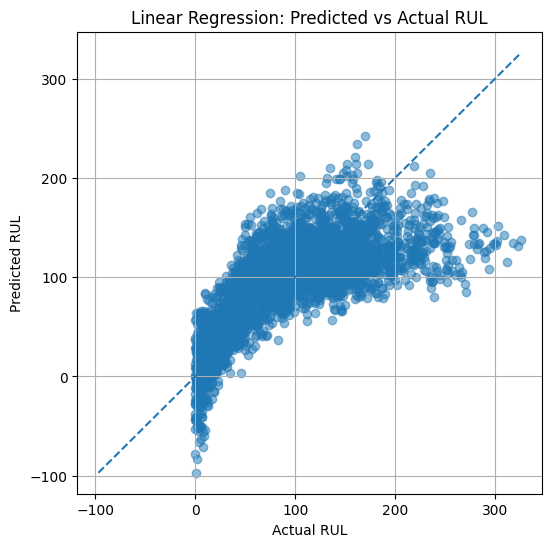

In [28]:
# Import matplotlib
import matplotlib.pyplot as plt

# Create figure
plt.figure(figsize=(6, 6))

# Scatter plot of actual vs predicted RUL
plt.scatter(yva, y_pred_lr, alpha=0.5)

# Compute min and max values for reference line
min_val = min(yva.min(), y_pred_lr.min())
max_val = max(yva.max(), y_pred_lr.max())

# Plot perfect prediction line
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

# Labels
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

# Title
plt.title("Linear Regression: Predicted vs Actual RUL")

# Grid
plt.grid(True)

# Show plot
plt.show()

1D CNN Results
RMSE: 19.95898504394387
MAE: 14.55135726928711
R2: 0.8958699107170105


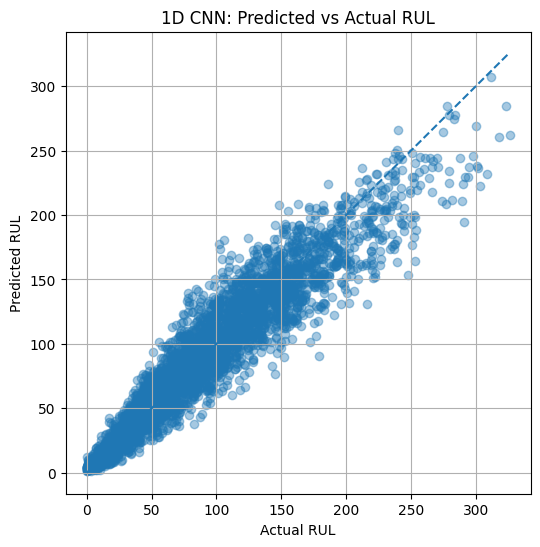

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import torch

# Set model to evaluation mode
model_1dcnn.eval()

# Lists to store values
actual_1d = []
predicted_1d = []

# Disable gradients
with torch.no_grad():
    for xb, yb in val_loader:   # make sure this matches your loader name

        xb = xb.to(device)
        yb = yb.to(device)

        preds = model_1dcnn(xb)
        preds = preds.view(-1)

        actual_1d.extend(yb.cpu().numpy())
        predicted_1d.extend(preds.cpu().numpy())

# Convert to numpy arrays
actual_1d = np.array(actual_1d)
predicted_1d = np.array(predicted_1d)

# Metrics
mse_1d = mean_squared_error(actual_1d, predicted_1d)
rmse_1d = np.sqrt(mse_1d)
mae_1d = mean_absolute_error(actual_1d, predicted_1d)
r2_1d = r2_score(actual_1d, predicted_1d)

# Print results
print("1D CNN Results")
print("RMSE:", rmse_1d)
print("MAE:", mae_1d)
print("R2:", r2_1d)

# Plot
plt.figure(figsize=(6,6))
plt.scatter(actual_1d, predicted_1d, alpha=0.4)

min_val = min(actual_1d.min(), predicted_1d.min())
max_val = max(actual_1d.max(), predicted_1d.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("1D CNN: Predicted vs Actual RUL")

plt.grid(True)
plt.show()

2D CNN Results
MSE : 738.398193359375
RMSE: 27.173483276153153
MAE : 18.77118492126465
R2  : 0.8069854974746704


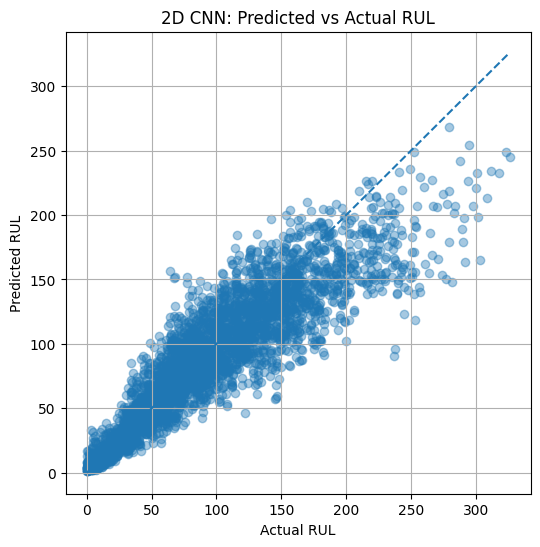

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import torch

# Set 2D model to evaluation mode
model_2d.eval()

# Create empty lists
targets_2d = []
preds_2d = []

# Turn off gradients
with torch.no_grad():

    # Loop through validation data
    for xb, yb in val_loader_2d:

        # Move input to device
        xb = xb.to(device)

        # Get model prediction
        pred = model_2d(xb)

        # Store predictions
        preds_2d.append(pred.cpu().numpy())

        # Store actual values
        targets_2d.append(yb.numpy())

# Convert predictions to one flat array
preds_2d = np.vstack(preds_2d).ravel()

# Convert targets to one flat array
targets_2d = np.vstack(targets_2d).ravel()

# Calculate metrics
mse_2d = mean_squared_error(targets_2d, preds_2d)
rmse_2d = np.sqrt(mse_2d)
mae_2d = mean_absolute_error(targets_2d, preds_2d)
r2_2d = r2_score(targets_2d, preds_2d)

# Print results
print("2D CNN Results")
print("MSE :", mse_2d)
print("RMSE:", rmse_2d)
print("MAE :", mae_2d)
print("R2  :", r2_2d)

# Create plot
plt.figure(figsize=(6, 6))

# Plot actual vs predicted RUL
plt.scatter(targets_2d, preds_2d, alpha=0.4)

# Create perfect prediction line
min_val = min(targets_2d.min(), preds_2d.min())
max_val = max(targets_2d.max(), preds_2d.max())

# Plot perfect prediction line
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

# Add labels
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

# Add title
plt.title("2D CNN: Predicted vs Actual RUL")

# Add grid
plt.grid(True)

# Show plot
plt.show()

LSTM Metrics and Graph

LSTM Results
MSE : 162.33160400390625
RMSE: 12.74094203753813
MAE : 8.932706832885742
R2  : 0.9575671553611755


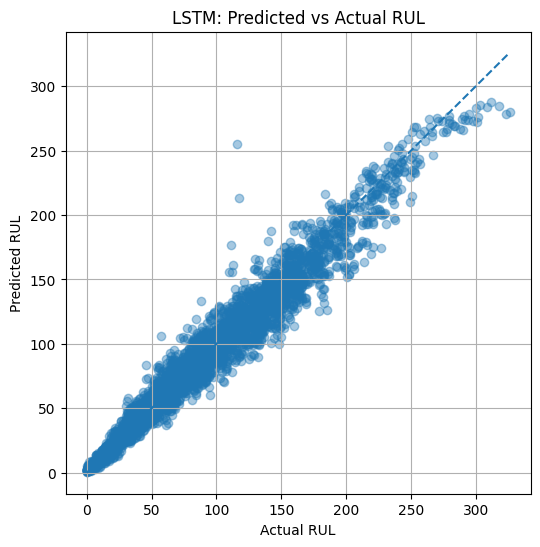

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import torch

# Set LSTM model to evaluation mode
model.eval()

# Create empty lists
targets_lstm = []
preds_lstm = []

# Turn off gradients
with torch.no_grad():

    # Loop through validation data
    for xb, yb in val_loader:

        # If shape is batch, 24, 30 then convert to batch, 30, 24
        if xb.shape[1] == 24 and xb.shape[2] == 30:
            xb = xb.permute(0, 2, 1)

        # Move input to device
        xb = xb.to(device)

        # Get model prediction
        pred = model(xb)

        # Store predictions
        preds_lstm.append(pred.cpu().numpy())

        # Store actual values
        targets_lstm.append(yb.numpy())

# Convert predictions to flat array
preds_lstm = np.vstack(preds_lstm).ravel()

# Convert targets to flat array
targets_lstm = np.vstack(targets_lstm).ravel()

# Calculate metrics
mse_lstm = mean_squared_error(targets_lstm, preds_lstm)
rmse_lstm = np.sqrt(mse_lstm)
mae_lstm = mean_absolute_error(targets_lstm, preds_lstm)
r2_lstm = r2_score(targets_lstm, preds_lstm)

# Print results
print("LSTM Results")
print("MSE :", mse_lstm)
print("RMSE:", rmse_lstm)
print("MAE :", mae_lstm)
print("R2  :", r2_lstm)

# Create plot
plt.figure(figsize=(6, 6))

# Plot actual vs predicted RUL
plt.scatter(targets_lstm, preds_lstm, alpha=0.4)

# Create perfect prediction line
min_val = min(targets_lstm.min(), preds_lstm.min())
max_val = max(targets_lstm.max(), preds_lstm.max())

# Plot reference line
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

# Add labels
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

# Add title
plt.title("LSTM: Predicted vs Actual RUL")

# Add grid
plt.grid(True)

# Show plot
plt.show()

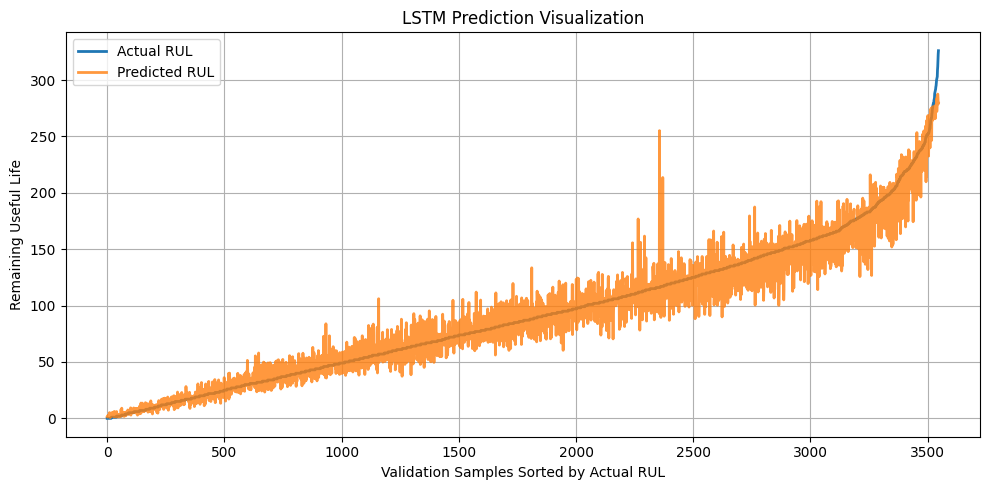

In [37]:
# Import libraries
import matplotlib.pyplot as plt
import numpy as np

# Choose which model predictions to show
# Recommended: use LSTM because it is your best model
actual = targets_lstm
predicted = preds_lstm

# Sort samples by actual RUL so the plot is easier to read
sort_idx = np.argsort(actual)

# Apply sorting
actual_sorted = actual[sort_idx]
predicted_sorted = predicted[sort_idx]

# Create figure
plt.figure(figsize=(10, 5))

# Plot actual RUL
plt.plot(actual_sorted, label="Actual RUL", linewidth=2)

# Plot predicted RUL
plt.plot(predicted_sorted, label="Predicted RUL", linewidth=2, alpha=0.8)

# Add labels
plt.xlabel("Validation Samples Sorted by Actual RUL")
plt.ylabel("Remaining Useful Life")

# Add title
plt.title("LSTM Prediction Visualization")

# Add legend
plt.legend()

# Add grid
plt.grid(True)

# Improve layout
plt.tight_layout()

# Show plot
plt.show()

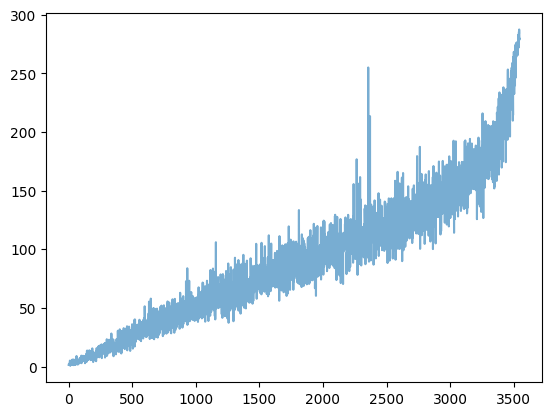

In [38]:
plt.plot(predicted_sorted, label="Predicted RUL", linewidth=1.5, alpha=0.6)

In [39]:
import torch.nn as nn

class BiLSTMRegressor(nn.Module):
    def __init__(self, input_size=24, hidden_size=64, num_layers=2):
        super().__init__()

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True
        )

        # Because bidirectional doubles hidden size
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)              # shape: (batch, seq, hidden*2)
        out = out[:, -1, :]                # last timestep
        out = self.fc(out)
        return out

# Initialize model
model_bilstm = BiLSTMRegressor().to(device)

BiLSTM Results
RMSE: 112.17935207180508
MAE : 93.5856704711914
R2  : -2.289464235305786


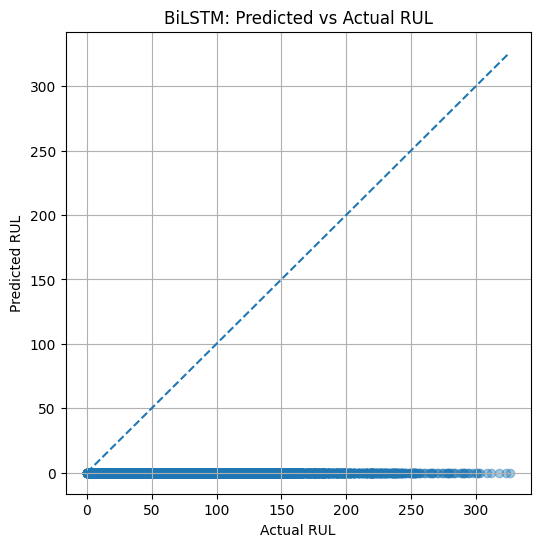

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import torch

# Eval mode
model_bilstm.eval()

targets_bi = []
preds_bi = []

with torch.no_grad():
    for xb, yb in val_loader:

        # Fix shape for LSTM/BiLSTM
        if xb.shape[1] == 24 and xb.shape[2] == 30:
            xb = xb.permute(0, 2, 1)

        xb = xb.to(device)

        pred = model_bilstm(xb)

        preds_bi.append(pred.cpu().numpy())
        targets_bi.append(yb.numpy())

# Convert
preds_bi = np.vstack(preds_bi).ravel()
targets_bi = np.vstack(targets_bi).ravel()

# Metrics
mse_bi = mean_squared_error(targets_bi, preds_bi)
rmse_bi = np.sqrt(mse_bi)
mae_bi = mean_absolute_error(targets_bi, preds_bi)
r2_bi = r2_score(targets_bi, preds_bi)

print("BiLSTM Results")
print("RMSE:", rmse_bi)
print("MAE :", mae_bi)
print("R2  :", r2_bi)

# Plot
plt.figure(figsize=(6,6))
plt.scatter(targets_bi, preds_bi, alpha=0.4)

min_val = min(targets_bi.min(), preds_bi.min())
max_val = max(targets_bi.max(), preds_bi.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("BiLSTM: Predicted vs Actual RUL")

plt.grid(True)
plt.show()

In [41]:
print("LSTM RMSE:", rmse_lstm)
print("BiLSTM RMSE:", rmse_bi)

LSTM RMSE: 12.74094203753813
BiLSTM RMSE: 112.17935207180508


In [42]:
rmse_lstm, mae_lstm, r2_lstm
rmse_bi, mae_bi, r2_bi

(np.float64(112.17935207180508), 93.5856704711914, -2.289464235305786)

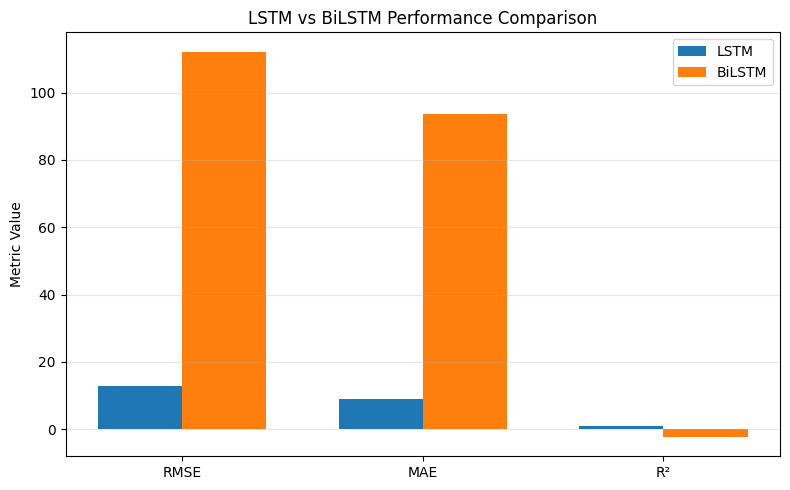

In [43]:
import matplotlib.pyplot as plt
import numpy as np

# Metric names
metrics = ["RMSE", "MAE", "R²"]

# LSTM metric values
lstm_values = [rmse_lstm, mae_lstm, r2_lstm]

# BiLSTM metric values
bilstm_values = [rmse_bi, mae_bi, r2_bi]

# X positions
x = np.arange(len(metrics))

# Bar width
width = 0.35

# Create figure
plt.figure(figsize=(8, 5))

# Plot LSTM bars
plt.bar(x - width/2, lstm_values, width, label="LSTM")

# Plot BiLSTM bars
plt.bar(x + width/2, bilstm_values, width, label="BiLSTM")

# Add x labels
plt.xticks(x, metrics)

# Add y label
plt.ylabel("Metric Value")

# Add title
plt.title("LSTM vs BiLSTM Performance Comparison")

# Add legend
plt.legend()

# Add grid
plt.grid(axis="y", alpha=0.3)

# Improve layout
plt.tight_layout()

# Show plot
plt.show()